In [31]:
%matplotlib inline
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath('')), 'Utilities'))
import numpy as np
import matplotlib.pyplot as plt
import phasecurve_utils
import kepler_utils

In [32]:
t0=0.

# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period (days)
rp = 0.02                                   #planet radius (in units of stellar radii)
rs = 0.68                                   # stellar radius (in units of solar radii)
a_AU = 0.007                                #semi-major axis (in AU)
a = kepler_utils.AU_to_RS(a_AU, rs)        #semi-major axis (in units of stellar radii)
incl = 86.3                                 #orbital inclination (in degrees)
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron (in degrees)
fp = 142e-6                                 #planet-to-star flux ratio / eclipse depth (integrated day-side flux)



A=0.5                                       # Phase Curve Amplitude ( A = 1 - F_p,min / F_p,max = (T_night / T_day)^4 )

### Spiderman

In [33]:
import spiderman as sp

In [34]:
spider_params = sp.ModelParams(brightness_model="zhang")
spider_params.n_layers= 20

In [35]:
spider_params.t0= t0                # Central time of PRIMARY transit [days]
spider_params.per= period           # Period [days]
spider_params.a_abs= a_AU           # The absolute value of the semi-major axis [AU]
spider_params.inc= incl             # Inclination [degrees]
spider_params.ecc= ecc              # Eccentricity
spider_params.w= w                  # Argument of periastron
spider_params.rp= rp                # Planet to star radius ratio
spider_params.a= a                  # Semi-major axis scaled by stellar radius
spider_params.p_u1= 0.5             # Planetary limb darkening parameter
spider_params.p_u2= 0.1             # Planetary limb darkening parameter

In [36]:
spider_params.xi= 0.                # Ratio of radiative to advective timescale
spider_params.T_n= 1128             # Temperature of nightside [K]
spider_params.delta_T= 942          # Day-night temperature contrast [K]
spider_params.T_s = 4600            # Temperature of the star [K]

In [37]:
spider_params.l1 = 1.1e-6       # The starting wavelength in meters
spider_params.l2 = 1.7e-6       # The ending wavelength in meters

In [45]:
min_temp = spider_params.T_n-50
max_temp = spider_params.T_n + spider_params.delta_T

In [46]:
t= spider_params.t0 + np.linspace(0, spider_params.per,100)

#### Phase Curve

no stellar models provided, using blackbody approximation


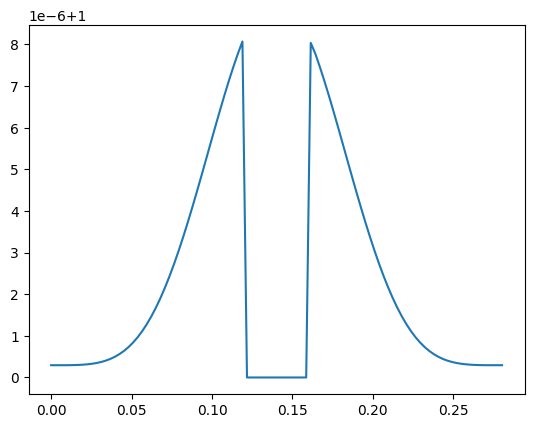

In [47]:
lc = spider_params.lightcurve(t)
plt.plot(t,lc)

#### Brightness Maps

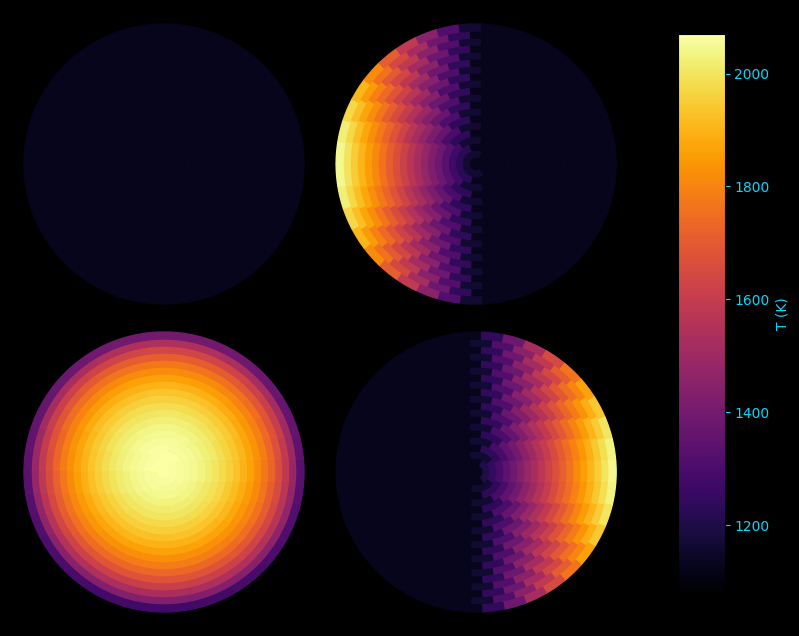

In [48]:
spider_params.plot_quad(min_temp=min_temp,max_temp=max_temp,temp_map=True,theme='black')
plt.show()

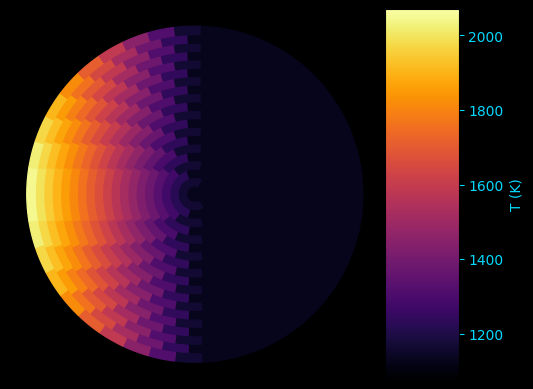

In [50]:
phase = 0.25
spider_params.plot_planet(phase,use_phase=True,min_temp=min_temp,max_temp=max_temp,temp_map=True, theme='black')
plt.show()